# NumPy Performance Techniques and Broadcasting

**Broadcasting** lets NumPy combine arrays of different shapes without copying data: subtract a mean per column, compare every point with every other point, apply a weight to each channel. Together with vectorisation and awareness of memory, it turns slow loops into fast array code.

**After this lesson you can:**

1. Apply the three broadcasting rules and predict result shapes.
2. Standardise data and compute distance matrices without loops.
3. Measure the speed of loops vs vectorised code, and the memory cost of intermediates.
4. Use in-place operations, `np.einsum`, and understand strides and memory layout.

**Data:** Palmer penguins and synthetic points for scaling tests.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])   # NOAA daily weather, Seattle

import json

penguins = pd.DataFrame(json.loads(datasets.fetch("penguins.json").read_text()))
cols = ["Beak Length (mm)", "Beak Depth (mm)", "Flipper Length (mm)", "Body Mass (g)"]
X = penguins[cols].dropna().to_numpy(dtype=float)
species = penguins.dropna(subset=cols)["Species"].to_numpy()
print(X.shape)

(342, 4)


## 1. The Broadcasting Rules

To combine arrays of shapes `A` and `B`, NumPy compares the dimensions **from the right**:

1. If the arrays have different numbers of dimensions, prepend 1s to the shorter shape.
2. Two dimensions are compatible if they are **equal** or one of them is **1**.
3. A dimension of size 1 is stretched (virtually, without copying) to the other size.

| `A` | `B` | Result |
| :--- | :--- | :--- |
| `(342, 4)` | `(4,)` | `(342, 4)` — one value per column |
| `(342, 1)` | `(1, 342)` | `(342, 342)` — every pair |
| `(3, 4)` | `(3,)` | error: 4 ≠ 3 |

In [2]:
for a, b in [((342, 4), (4,)), ((342, 1), (1, 342)), ((8, 1, 6, 1), (7, 1, 5)), ((3, 4), (3,))]:
    try:
        print(f"{a!s:<14} + {b!s:<10} -> {np.broadcast_shapes(a, b)}")
    except ValueError:
        print(f"{a!s:<14} + {b!s:<10} -> error (incompatible)")

(342, 4)       + (4,)       -> (342, 4)
(342, 1)       + (1, 342)   -> (342, 342)
(8, 1, 6, 1)   + (7, 1, 5)  -> (8, 7, 6, 5)
(3, 4)         + (3,)       -> error (incompatible)


## 2. Standardise Columns

**Standardisation** (z-scores) puts every feature on the same scale: $z = (x - \mu) / \sigma$, per column. With broadcasting, the column means `(4,)` apply to every row of `(342, 4)`.

In [3]:
mu, sigma = X.mean(axis=0), X.std(axis=0)
Z = (X - mu) / sigma                                # (342, 4) - (4,) -> (342, 4)
print("means after :", Z.mean(axis=0).round(6))
print("stds after  :", Z.std(axis=0).round(6))

row_share = X / X.sum(axis=1, keepdims=True)       # keepdims keeps (342, 1) so it broadcasts per row
print("keepdims shape:", X.sum(axis=1, keepdims=True).shape, "| each row sums to", row_share[0].sum())

means after : [ 0. -0. -0.  0.]
stds after  : [1. 1. 1. 1.]
keepdims shape: (342, 1) | each row sums to 1.0


## 3. Pairwise Distances: Loops vs Broadcasting

The Euclidean distance between every pair of penguins (in standardised units) is a `(342, 342)` matrix. With broadcasting, `Z[:, None, :] - Z[None, :, :]` has shape `(342, 342, 4)`: all differences at once.

In [4]:
def dist_loops(P):
    n = len(P)
    D = np.empty((n, n))
    for i in range(n):
        for j in range(n):
            D[i, j] = np.sqrt(((P[i] - P[j]) ** 2).sum())
    return D

def dist_broadcast(P):
    diff = P[:, None, :] - P[None, :, :]           # (n, n, d)
    return np.sqrt((diff ** 2).sum(axis=-1))

def dist_matmul(P):
    sq = (P ** 2).sum(axis=1)                      # ||a-b||² = ||a||² + ||b||² - 2 a·b
    return np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * P @ P.T, 0))

t = time.perf_counter(); D1 = dist_loops(Z); t_loop = time.perf_counter() - t
t = time.perf_counter(); D2 = dist_broadcast(Z); t_bc = time.perf_counter() - t
t = time.perf_counter(); D3 = dist_matmul(Z); t_mm = time.perf_counter() - t
print(f"loops {t_loop * 1000:8.1f} ms | broadcasting {t_bc * 1000:6.1f} ms | matmul trick {t_mm * 1000:6.1f} ms")
print("same results:", np.allclose(D1, D2), np.allclose(D2, D3, atol=1e-6))   # the matmul trick has tiny rounding errors

np.fill_diagonal(D2, np.inf)
nearest = D2.argmin(axis=1)
print(f"nearest neighbour has the same species for {np.mean(species[nearest] == species):.1%} of penguins")

loops    242.6 ms | broadcasting    4.3 ms | matmul trick    3.9 ms
same results: True True
nearest neighbour has the same species for 98.2% of penguins


A nearest-neighbour classifier (k-NN, M16) with four measurements already identifies the species of almost every penguin.

## 4. Scaling: Time and Memory

Broadcasting creates the full `(n, n, d)` intermediate array in memory. The matrix-product version needs only `(n, n)` and uses optimised BLAS routines. The experiment measures both for growing *n* (synthetic points in 16 dimensions).

   n  broadcast_ms  matmul_ms  broadcast_intermediate_MB  matmul_intermediate_MB
 250           9.5        7.1                        8.0                     0.5
 500          41.8        9.6                       32.0                     2.0
1000         164.3       11.9                      128.0                     8.0
2000         882.9       33.4                      512.0                    32.0
3000        2529.4       75.7                     1152.0                    72.0


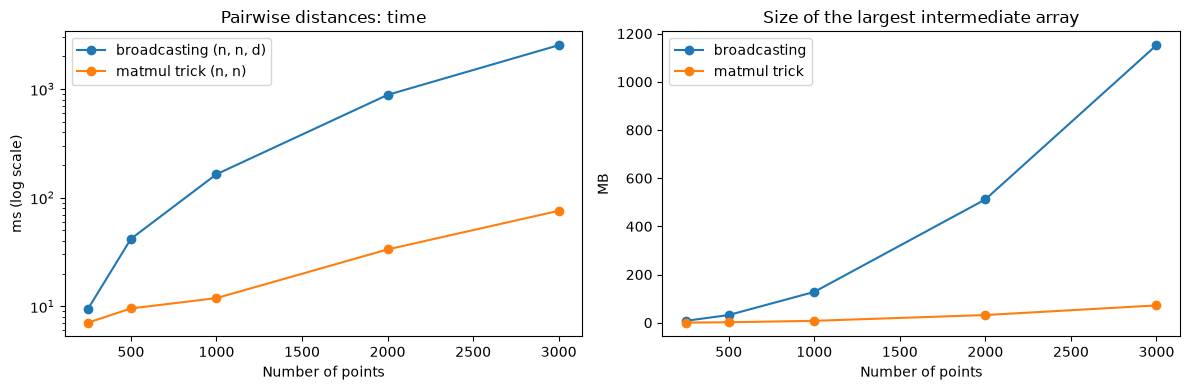

In [5]:
rng = np.random.default_rng(0)
rows = []
for n in [250, 500, 1000, 2000, 3000]:
    P = rng.normal(size=(n, 16))
    t = time.perf_counter(); dist_broadcast(P); tb = time.perf_counter() - t
    t = time.perf_counter(); dist_matmul(P); tm = time.perf_counter() - t
    rows.append({"n": n, "broadcast_ms": tb * 1000, "matmul_ms": tm * 1000,
                 "broadcast_intermediate_MB": n * n * 16 * 8 / 1e6, "matmul_intermediate_MB": n * n * 8 / 1e6})
scaling = pd.DataFrame(rows)
print(scaling.round(1).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(scaling["n"], scaling["broadcast_ms"], marker="o", label="broadcasting (n, n, d)")
ax1.plot(scaling["n"], scaling["matmul_ms"], marker="o", label="matmul trick (n, n)")
ax1.set(yscale="log", title="Pairwise distances: time", xlabel="Number of points", ylabel="ms (log scale)")
ax1.legend()
ax2.plot(scaling["n"], scaling["broadcast_intermediate_MB"], marker="o", label="broadcasting")
ax2.plot(scaling["n"], scaling["matmul_intermediate_MB"], marker="o", label="matmul trick")
ax2.set(title="Size of the largest intermediate array", xlabel="Number of points", ylabel="MB")
ax2.legend()
plt.tight_layout()
plt.show()

## 5. In-Place Operations, `einsum`, and Memory Layout

- **In-place** operations (`a *= 2`, `np.multiply(a, 2, out=a)`) write into existing memory instead of allocating a new array.
- **`np.einsum`** writes many array operations (sums, products, transposes) in index notation: `"ij,ij->i"` is a row-wise dot product.
- **Strides** tell how many bytes to jump to the next element of each axis. A transpose only changes strides, no data moves. Contiguous memory is faster to scan than strided memory.

In [6]:
big = rng.normal(size=(3000, 3000))
t = time.perf_counter(); tmp = big * 2.0; t_new = time.perf_counter() - t
t = time.perf_counter(); big *= 2.0; t_inplace = time.perf_counter() - t
print(f"new array {t_new * 1000:.1f} ms | in place {t_inplace * 1000:.1f} ms")

rowdot = np.einsum("ij,ij->i", Z, Z)
print("einsum row-wise dot equals sum of squares:", np.allclose(rowdot, (Z ** 2).sum(axis=1)))

print("strides of big   :", big.strides, "| C-contiguous:", big.flags["C_CONTIGUOUS"])
print("strides of big.T :", big.T.strides, "| C-contiguous:", big.T.flags["C_CONTIGUOUS"])
t = time.perf_counter(); big.sum(axis=1); t_rows = time.perf_counter() - t
t = time.perf_counter(); np.ascontiguousarray(big.T).sum(axis=1); t_copy = time.perf_counter() - t
t = time.perf_counter(); big.T.sum(axis=1); t_strided = time.perf_counter() - t
print(f"sum along rows (contiguous) {t_rows * 1000:.1f} ms | along the transposed view {t_strided * 1000:.1f} ms")

new array 33.7 ms | in place 11.8 ms
einsum row-wise dot equals sum of squares: True
strides of big   : (24000, 8) | C-contiguous: True
strides of big.T : (8, 24000) | C-contiguous: False
sum along rows (contiguous) 8.3 ms | along the transposed view 6.2 ms


*Insight: Vectorise first (remove Python loops), then watch memory: broadcasting is elegant but can create huge intermediate arrays. When an expression can be written as a matrix product, BLAS is usually the fastest and leanest option.*

## Real-World Use Case or Analogy

Broadcasting is like a **teacher who writes one correction on the board** instead of on every student's sheet: everybody applies it to their own work. The memory warning is like photocopying the board for every student: correct, but wasteful for a large class.

Vector databases, k-means clustering and attention in transformers are all built on pairwise similarities computed with the matrix-product trick (M26, M28). GPU libraries use the same broadcasting rules as NumPy.